# 02 · The physics of the pressure drop

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p03_ro_fouling/notebooks/02_physics.ipynb)

The feed-channel pressure drop rises when fouling narrows the channel — but it also rises when the
plant simply pushes more water through, or when the water is colder. Before any forecast, those
two have to be divided out. **How** they are divided out turns out to matter more than any model
choice in this project.

Script version: `projects/p03_ro_fouling/step2_physics.py` · record: `VALIDATION.md`, sections 5–7.

In [1]:
# Setup. In Google Colab this installs the package from GitHub (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz]"
import os, subprocess, sys
REF = "main"        # before the Project 3 pull request is merged, use "p03-ro-fouling"
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"chemai[viz] @ git+https://github.com/EngMtaleb/chemai.git@{REF}"], check=True)
    os.environ["CHEMAI_DATA_DIR"] = "/content/data"     # where the deposit is downloaded

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
COL = {"A": "#2a6fb0", "B": "#128c84", "C": "#a8782f"}

## 1. Water viscosity and the temperature correction

Viscosity follows the Vogel equation (0.89 mPa·s at 25 °C). Membrane permeability follows a
vendor temperature-correction factor, TCF = exp(E (1/298.15 − 1/T)).

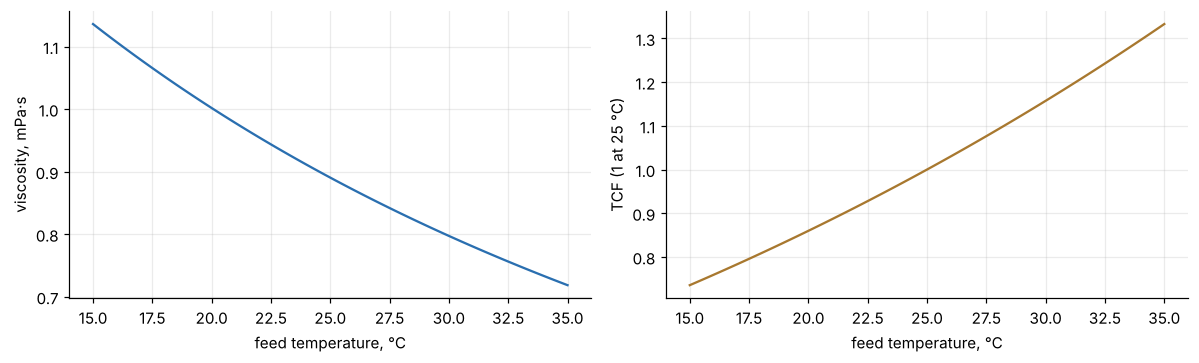

viscosity at 25 °C: 0.890 mPa·s
±5 K changes viscosity by [ 0.125 -0.105]


In [2]:
from chemai.features.ro_physics import tcf, water_viscosity

T = np.linspace(15, 35, 81)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(T, water_viscosity(T) * 1e3, color="#2a6fb0"); axes[0].set_ylabel("viscosity, mPa·s")
axes[1].plot(T, tcf(T), color="#a8782f"); axes[1].set_ylabel("TCF (1 at 25 °C)")
for ax in axes: ax.set_xlabel("feed temperature, °C")
plt.tight_layout(); plt.show()
print(f"viscosity at 25 °C: {water_viscosity(25.0) * 1e3:.3f} mPa·s")
print("±5 K changes viscosity by", np.round(water_viscosity(np.array([20.0, 30.0])) / water_viscosity(25.0) - 1, 3))

## 2. Friction in a spacer-filled channel

With a friction factor f ~ Re^−m, the pressure drop scales as

**ΔP ∝ Q^(2−m) · μ^m**

m is about 0.3 (Schock & Miquel, 1987) or 0.2 (CFD), so the **flow exponent 2 − m is 1.7–1.8**.
Membrane vendors normalise with a flow ratio raised to 1.0–1.5.

A thought experiment: a perfectly clean train, production raised by 20 %. What does each
normalisation report?

In [3]:
q_ratio = 1.20
true_rise = q_ratio ** 1.75                    # what physics does to dP
for n, name in ((1.0, "linear ratio"), (1.5, "vendor 1.5"), (1.75, "physics 1.75")):
    dp_norm = true_rise / q_ratio ** n
    print(f"{name:13s} reads DP_norm {dp_norm:.3f}  ->  invented fouling {100 * (dp_norm - 1):+.1f} %")

linear ratio  reads DP_norm 1.147  ->  invented fouling +14.7 %
vendor 1.5    reads DP_norm 1.047  ->  invented fouling +4.7 %
physics 1.75  reads DP_norm 1.000  ->  invented fouling +0.0 %


A linear ratio turns a 20 % production increase into **+15 % of "fouling"** — the entire vendor
review margin, with nothing on the membrane. The vendor exponent still invents almost 5 %.

## 3. The same thing on a simulated plant

Three simulated plants (one per fouling law), where the true fouling is known. Each normalisation
is applied to what the plant would log; the ratio to the truth shows the fouling it invents.
(The script uses 15 plants; the numbers here are from 3.)

In [4]:
from chemai.data.ro_sim import generate_plants
from chemai.evaluation.fouling_eval import plant_view

runs = generate_plants(3, seed=3003)
NORMS = {"linear ratio (1.0)": (1.0, 0.0), "vendor (1.5)": (1.5, 0.25),
         "physics (1.75)": (1.75, 0.25), "plant's own fit": ("fit", None)}

def invented(run, fe, ve):
    v = plant_view(run, fe, ve)
    truth = run.daily.set_index(["train", "day"])["dp_true"]
    out = []
    for tr, g in v.groupby("train"):
        r = g["dp_norm_raw"].to_numpy() / truth.loc[list(zip(g["train"], g["day"]))].to_numpy()
        out.append(r / np.median(r))
    return np.concatenate(out)

rows = []
for name, (fe, ve) in NORMS.items():
    r = np.concatenate([invented(run, fe, ve) for run in runs])
    rows.append(dict(normalisation=name, sd_percent=round(100 * r.std(), 2),
                     p5=round(100 * (np.quantile(r, 0.05) - 1), 1), p95=round(100 * (np.quantile(r, 0.95) - 1), 1)))
pd.DataFrame(rows)

,normalisation,sd_percent,p5,p95
0,linear ratio (1.0),12.04,-17.8,18.3
1,vendor (1.5),4.81,-6.5,7.4
2,physics (1.75),2.69,-3.7,3.8
3,plant's own fit,2.72,-3.8,3.9


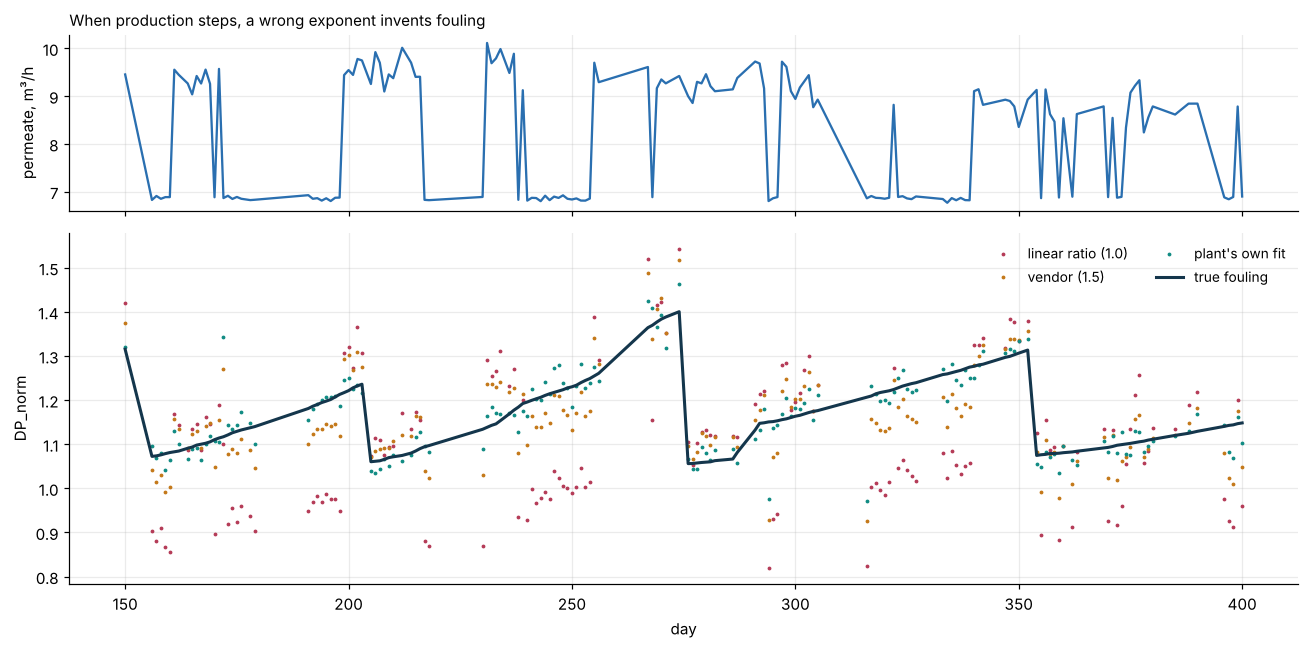

In [5]:
run = runs[0]; tr = "A"
g = run.daily[(run.daily["train"] == tr) & run.daily["recorded"] & run.daily["day"].between(150, 400)]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw=dict(height_ratios=[1, 2]))
axes[0].plot(g["day"], g["perm_flow"], color="#2a6fb0"); axes[0].set_ylabel("permeate, m³/h")
for name, col in (("linear ratio (1.0)", "#b53c58"), ("vendor (1.5)", "#c4791b"), ("plant's own fit", "#128c84")):
    fe, ve = NORMS[name]
    v = plant_view(run, fe, ve)
    v = v[(v["train"] == tr) & v["day"].between(150, 400)]
    k = np.median(v["dp_norm_raw"].to_numpy() / g["dp_true"].to_numpy())
    axes[1].plot(v["day"], v["dp_norm_raw"] / k, ".", ms=3, color=col, label=name)
axes[1].plot(g["day"], g["dp_true"], color="#14364c", lw=2, label="true fouling")
axes[1].set_ylabel("DP_norm"); axes[1].set_xlabel("day"); axes[1].legend(frameon=False, ncol=2, fontsize=9)
axes[0].set_title("When production steps, a wrong exponent invents fouling", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 4. The plant can measure its own exponent

Take logs and day-to-day differences of ΔP ∝ Q^n · μ^(2−n):

**d ln ΔP − 2 d ln μ = n · (d ln Q − d ln μ)**

Every production change is a free experiment. `fit_flow_exponent` refuses when production barely
moved — steady operation cannot reveal n.

In [6]:
from chemai.features.ro_physics import fit_flow_exponent

rows = []
for i, run in enumerate(runs):
    for p in run.params.trains:
        g = run.daily[(run.daily["train"] == p.name) & run.daily["recorded"]]
        g = g[g["day"] <= g["day"].min() + 120]             # the first four months only
        dpt = fit_flow_exponent(g)                          # differential transmitter
        two_pt = fit_flow_exponent(g.drop(columns=["dp"]))  # feed minus concentrate pressure
        rows.append(dict(plant=i, train=p.name, true=round(2 - p.friction_m, 3),
                         fitted_dpt=dpt["n"] if dpt["n"] is not None else np.nan,
                         fitted_two_pt=two_pt["n"] if two_pt["n"] is not None else np.nan, steps=dpt["steps"]))
t = pd.DataFrame(rows)
print("mean absolute error: DP transmitter", round((t.fitted_dpt - t.true).abs().mean(), 3),
      "| two pressure transmitters", round((t.fitted_two_pt - t.true).abs().mean(), 3))
t

mean absolute error: DP transmitter 0.031 | two pressure transmitters 0.105


,plant,train,true,fitted_dpt,fitted_two_pt,steps
0,0,A,1.797,1.771,1.899,71
1,0,B,1.797,1.864,2.052,29
2,0,C,1.797,1.782,2.074,66
3,1,A,1.750,1.789,1.822,69
4,1,B,1.750,1.776,1.799,46
5,1,C,1.750,1.738,1.699,86
6,2,A,1.742,1.711,1.662,78
7,2,B,1.742,1.713,1.723,71
8,2,C,1.742,1.773,1.783,101


In [7]:
# steady production: the fit says so instead of returning a number
g = runs[0].daily[(runs[0].daily["train"] == "A") & runs[0].daily["recorded"]].head(60).copy()
g["perm_flow"] = g["perm_flow"].median(); g["feed_flow"] = g["feed_flow"].median(); g["conc_flow"] = g["conc_flow"].median()
print(fit_flow_exponent(g)["note"])

production too steady to measure the exponent (55 day pairs, spread 0.022); use the physics value 1.75


## 5. The gap law: the pressure drop accelerates as the channel closes

ΔP ∝ gap^−n with n ≈ 2.2 (CFD) to 3 (a slit). Losing 10 % of the gap raises ΔP by about 26 %. The
question for a forecast is whether the curve bends enough, at the levels plants clean at, to make a
straight line wrong.

10 % gap loss -> DP_norm 1.261
largest sag below the straight chord between 1.00 and 1.30: 0.0145


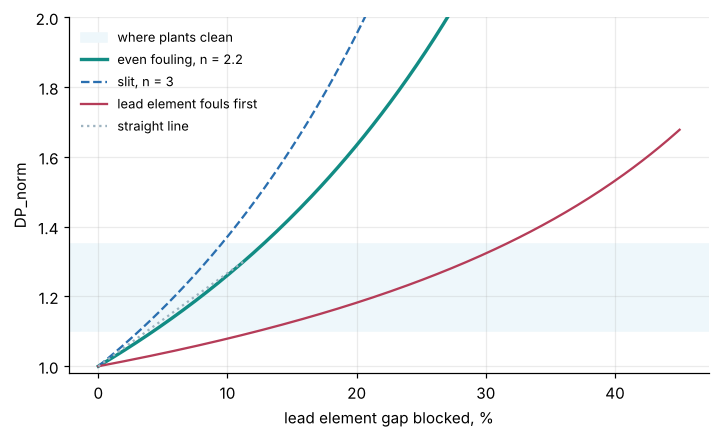

In [8]:
from chemai.features.ro_physics import dp_from_blockage

phi = np.linspace(0, 0.45, 200)
even = dp_from_blockage(phi, 2.2)
i30 = int(np.argmax(even >= 1.30))
chord = 1 + (even[i30] - 1) * phi / phi[i30]
print(f"10 % gap loss -> DP_norm {dp_from_blockage(0.10, 2.2):.3f}")
print(f"largest sag below the straight chord between 1.00 and 1.30: {np.max((chord - even)[: i30 + 1]):.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axhspan(1.10, 1.35, color="#eef7fb", label="where plants clean")
ax.plot(phi * 100, even, color="#128c84", lw=2.2, label="even fouling, n = 2.2")
ax.plot(phi * 100, dp_from_blockage(phi, 3.0), "--", color="#2a6fb0", label="slit, n = 3")
ax.plot(phi * 100, dp_from_blockage(phi, 2.2, lead_share=0.2, rest_ratio=0.15), color="#b53c58",
        label="lead element fouls first")
ax.plot(phi[: i30 + 1] * 100, chord[: i30 + 1], ":", color="#9db3c0", label="straight line")
ax.set_ylim(0.98, 2.0); ax.set_xlabel("lead element gap blocked, %"); ax.set_ylabel("DP_norm")
ax.legend(frameon=False, fontsize=8.5); plt.show()

It accelerates — but between 1.00 and 1.30 it bends only about 0.015 away from a straight line.
In the forecast tests this was worth one to two days; the straight line was kept (VALIDATION.md,
section 7).

## What this notebook settled

- A **linear flow ratio invents up to ±15–20 % of fouling**; the vendor exponent about ±7 %; the
  physics or the plant's own exponent about ±4 %.
- The plant can **measure its own exponent** from its own production changes — far better with a
  differential pressure transmitter than with two pressure transmitters.
- The gap law is right, and **barely matters below 1.3**.

Next: [03 · A plant whose truth is known](03_simulator.ipynb).